In [2]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset downloaded to:", dataset_path)


100%|██████████| 2.29G/2.29G [00:21<00:00, 113MB/s] 

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [3]:
import os
print(os.listdir(dataset_path))

['chest_xray']


In [4]:
from pathlib import Path

data_path = Path(dataset_path) / "chest_xray"


for item in list(data_path.iterdir()):
    print(item.name)

__MACOSX
chest_xray
test
train
val


In [5]:
from pathlib import Path

data_path = Path(dataset_path) / "chest_xray"

for split in ["train", "val", "test"]:
    split_path = data_path / split

    print(f"\n{split.upper()}:")

    for class_folder in split_path.iterdir():
        if class_folder.is_dir():
            print(f"  {class_folder.name}")


TRAIN:
  NORMAL
  PNEUMONIA

VAL:
  NORMAL
  PNEUMONIA

TEST:
  NORMAL
  PNEUMONIA


In [6]:
from pathlib import Path

data_path = Path(dataset_path) / "chest_xray"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for class_name in ["NORMAL", "PNEUMONIA"]:
        class_path = data_path / split / class_name

        images = [
            file for file in class_path.iterdir()
            if file.is_file() and file.suffix.lower() in image_extensions
        ]

        print(f"{class_name}: {len(images)} images")


TRAIN
NORMAL: 1341 images
PNEUMONIA: 3875 images

VAL
NORMAL: 8 images
PNEUMONIA: 8 images

TEST
NORMAL: 234 images
PNEUMONIA: 390 images


DATASET STRUCTURE

TRAIN
  NORMAL: folder exists
  PNEUMONIA: folder exists

VAL
  NORMAL: folder exists
  PNEUMONIA: folder exists

TEST
  NORMAL: folder exists
  PNEUMONIA: folder exists


IMAGE COUNTS

TRAIN
  NORMAL: 1341 images
  PNEUMONIA: 3875 images
  Total: 5216 images
  NORMAL percentage: 25.71%
  PNEUMONIA percentage: 74.29%

VAL
  NORMAL: 8 images
  PNEUMONIA: 8 images
  Total: 16 images
  NORMAL percentage: 50.00%
  PNEUMONIA percentage: 50.00%

TEST
  NORMAL: 234 images
  PNEUMONIA: 390 images
  Total: 624 images
  NORMAL percentage: 37.50%
  PNEUMONIA percentage: 62.50%


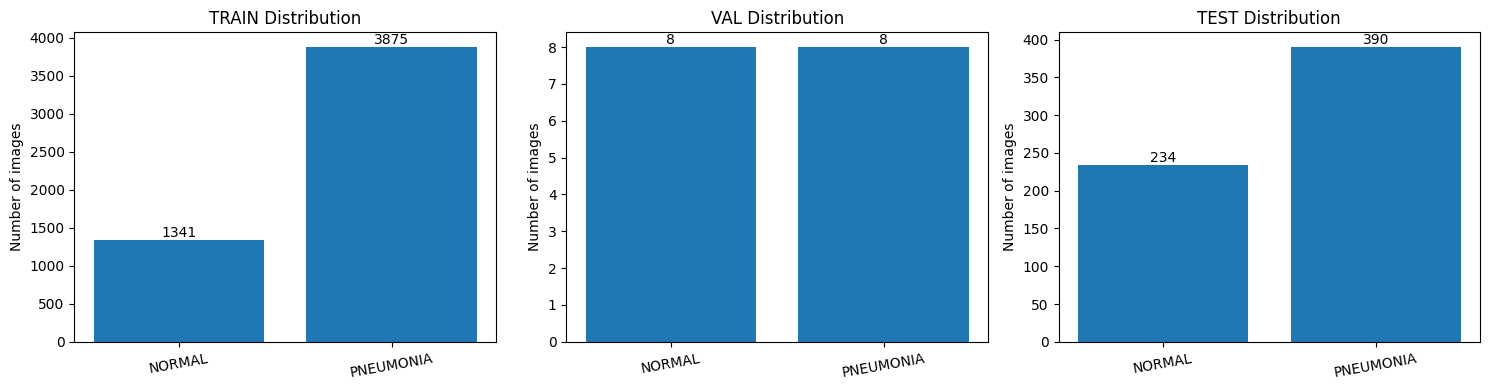

In [7]:
from pathlib import Path
import matplotlib.pyplot as plt


data_path = Path(dataset_path) / "chest_xray"


splits = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}


if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

print("DATASET STRUCTURE")
print("=" * 50)

for split in splits:
    split_path = data_path / split

    if not split_path.is_dir():
        print(f"Missing directory: {split}")
        continue

    print(f"\n{split.upper()}")

    for class_name in classes:
        class_path = split_path / class_name

        if not class_path.is_dir():
            print(f"  Missing class: {class_name}")
            continue

        print(f"  {class_name}: folder exists")


counts = {}

print("\n\nIMAGE COUNTS")
print("=" * 50)

for split in splits:
    counts[split] = {}

    print(f"\n{split.upper()}")

    for class_name in classes:
        class_path = data_path / split / class_name

        if not class_path.is_dir():
            counts[split][class_name] = 0
            print(f"  {class_name}: 0 (folder missing)")
            continue

        images = [
            file for file in class_path.rglob("*")
            if file.is_file()
            and file.suffix.lower() in image_extensions
        ]

        counts[split][class_name] = len(images)
        print(f"  {class_name}: {len(images)} images")

    total = sum(counts[split].values())
    print(f"  Total: {total} images")

    if total > 0:
        for class_name in classes:
            percentage = counts[split][class_name] / total * 100
            print(f"  {class_name} percentage: {percentage:.2f}%")


fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, split in zip(axes, splits):
    values = [counts[split][c] for c in classes]

    ax.bar(classes, values)
    ax.set_title(f"{split.upper()} Distribution")
    ax.set_ylabel("Number of images")
    ax.tick_params(axis="x", rotation=10)

    for i, value in enumerate(values):
        ax.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()

Checking image integrity...

Total corrupted images: 0


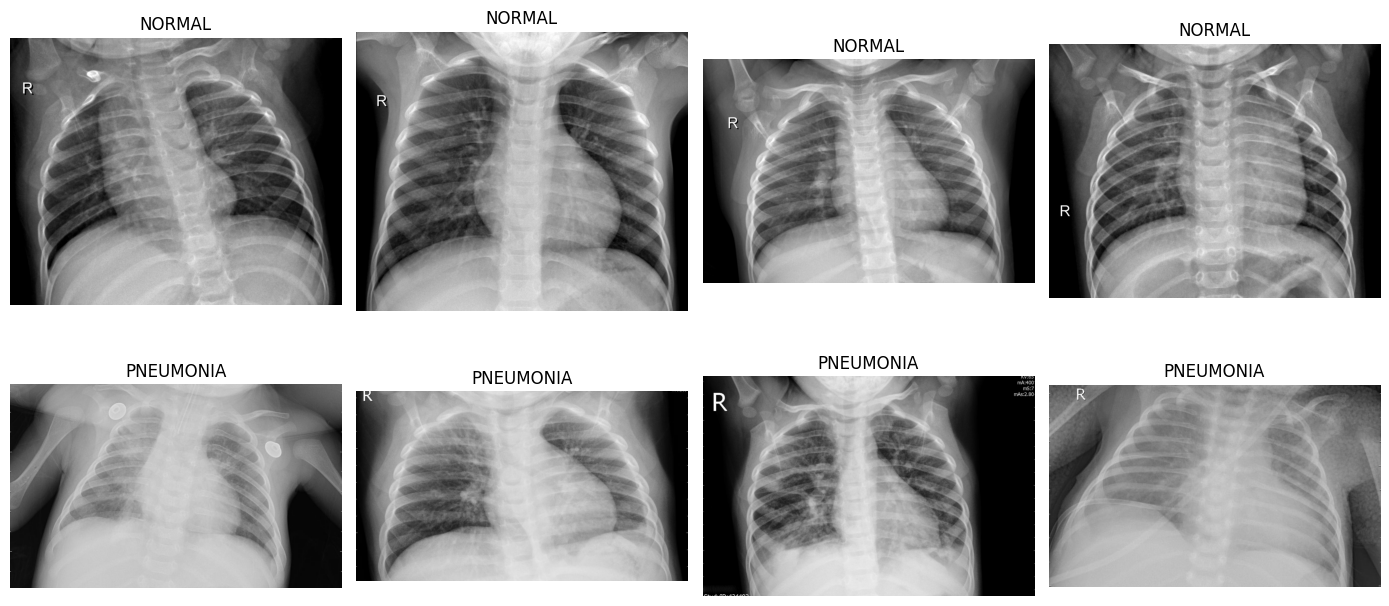

In [8]:
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import matplotlib.pyplot as plt
import random


data_path = Path(dataset_path) / "chest_xray"

splits = ["train", "val", "test"]
classes = ["NORMAL", "PNEUMONIA"]
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}


corrupted_images = []

print("Checking image integrity...")

for split in splits:
    for class_name in classes:
        class_path = data_path / split / class_name

        if not class_path.exists():
            print(f"Missing folder: {class_path}")
            continue

        for image_path in class_path.rglob("*"):
            if not image_path.is_file():
                continue

            if image_path.suffix.lower() not in image_extensions:
                continue

            try:
                with Image.open(image_path) as img:
                    img.verify()
            except (OSError, ValueError, UnidentifiedImageError):
                corrupted_images.append(image_path)

print(f"\nTotal corrupted images: {len(corrupted_images)}")

for image_path in corrupted_images[:10]:
    print(image_path)


random.seed(42)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, class_name in enumerate(classes):
    class_path = data_path / "train" / class_name

    images = [
        p for p in class_path.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
        and p not in corrupted_images
    ]

    selected_images = random.sample(images, min(4, len(images)))

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(selected_images):
            with Image.open(selected_images[col]) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(class_name)

plt.tight_layout()
plt.show()

Combined X: (5232, 180, 180, 1)
Combined y: (5232,)

Final dataset shapes:
X_train: (4185, 180, 180, 1)
y_train: (4185,)
X_val: (1047, 180, 180, 1)
y_val: (1047,)
X_test: (624, 180, 180, 1)
y_test: (624,)

Pixel minimum: 0.0
Pixel maximum: 1.0


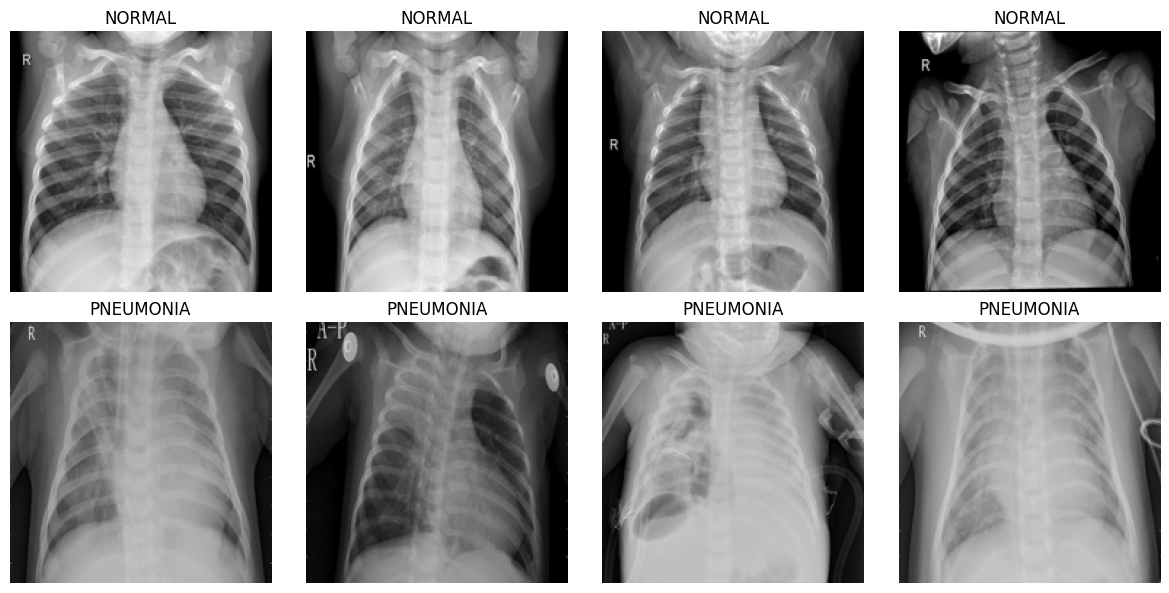

In [9]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


data_path = Path(dataset_path) / "chest_xray"

IMG_SIZE = (180, 180)
CLASSES = ["NORMAL", "PNEUMONIA"]
SPLITS = ["train", "val", "test"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def load_images(split):
    images = []
    labels = []

    for label, class_name in enumerate(CLASSES):
        class_path = data_path / split / class_name

        for image_path in sorted(class_path.rglob("*")):
            if not image_path.is_file():
                continue

            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            try:
                with Image.open(image_path) as img:
                    img = img.convert("L")
                    img = img.resize(IMG_SIZE)

                    image_array = np.array(img, dtype=np.float32)
                    images.append(image_array)
                    labels.append(label)

            except (OSError, ValueError) as error:
                print(f"Could not load {image_path}: {error}")

    X = np.array(images, dtype=np.float32)
    y = np.array(labels, dtype=np.int32)


    X /= 255.0


    X = X[..., np.newaxis]

    return X, y



X_train, y_train = load_images("train")
X_val, y_val = load_images("val")
X_test, y_test = load_images("test")

X_combined = np.concatenate([X_train, X_val], axis=0)
y_combined = np.concatenate([y_train, y_val], axis=0)

print("Combined X:", X_combined.shape)
print("Combined y:", y_combined.shape)

X_train, X_val, y_train, y_val = train_test_split(
    X_combined,
    y_combined,
    test_size=0.20,
    random_state=42,
    stratify=y_combined
)

# 4. Keep the test dataset unchanged
print("\nFinal dataset shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)





print("\nPixel minimum:", X_train.min())
print("Pixel maximum:", X_train.max())


fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for label, class_name in enumerate(CLASSES):
    indices = np.where(y_train == label)[0]
    selected = indices[:4]

    for col, idx in enumerate(selected):
        axes[label, col].imshow(
            X_train[idx].squeeze(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[label, col].set_title(class_name)
        axes[label, col].axis("off")

plt.tight_layout()
plt.show()

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.RandomZoom(height_factor=0.10, width_factor=0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")


tf.keras.utils.set_random_seed(42)


model = models.Sequential([
    layers.Input(shape=(180, 180, 1)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),


    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),


    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),


    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)


model.summary()

2026-10-23 11:45:33.601346: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-23 11:45:33.730553: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792755933.786759    1842 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792755933.802661    1842 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792755933.923796    1842 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 180, 180, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,929,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,022,785 (30.60 MB)

 Trainable params: 8,022,785 (30.60 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int32(0): np.float64(1.9392956441149212), np.int32(1): np.float64(0.6736960721184804)}


In [12]:
print(X_train.shape)

(4185, 180, 180, 1)


In [13]:
print("Number of training images:", len(X_train))
print("Number of validation images:", len(X_val))
print("Batch size:", model.input_shape)

Number of training images: 4185
Number of validation images: 1047
Batch size: (None, 180, 180, 1)


In [14]:
import tensorflow as tf
import time

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_chestscan_model.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    class_weight=class_weights,
    callbacks=callbacks
)

training_time = time.time() - start_time

print(f"Training time: {training_time:.2f} seconds")

Epoch 1/20


I0000 00:00:1792755943.915918    2198 cuda_dnn.cc:529] Loaded cuDNN version 90300


131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5931 - auc: 0.7084 - loss: 0.6013 - precision: 0.8467 - recall: 0.5477
Epoch 1: val_loss improved from inf to 0.20466, saving model to best_chestscan_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.5942 - auc: 0.7095 - loss: 0.6003 - precision: 0.8472 - recall: 0.5490 - val_accuracy: 0.9217 - val_auc: 0.9789 - val_loss: 0.2047 - val_precision: 0.9793 - val_recall: 0.9138 - learning_rate: 0.0010
Epoch 2/20
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8581 - auc: 0.9254 - loss: 0.3508 - precision: 0.9445 - recall: 0.8606
Epoch 2: val_loss improved from 0.20466 to 0.15324, saving model to best_chestscan_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.8582 - auc: 0.9256 - loss: 0.3505 - precision: 0.9446 - recall: 0.8605 - val_accuracy: 0.9436 - val_auc: 0.9858 - val_loss: 0.1532 - val_precision: 0.9787 - val_recall: 0.9447 - learning_rate: 0.0010
Epoch 3/20
129/131 ━━━━━━━━━━━━━━━━━

In [15]:
model.save("best_chestscan_model.keras")

print("Best model saved successfully!")

Best model saved successfully!


In [16]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

X_train shape: (4185, 180, 180, 1)
X_val shape: (1047, 180, 180, 1)
y_train shape: (4185,)
y_val shape: (1047,)


In [17]:
print("Classes:", np.unique(y_train))
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

model.summary()

Classes: [0 1]
Model input: (None, 180, 180, 1)
Model output: (None, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 180, 180, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,929,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,068,357 (91.81 MB)

 Trainable params: 8,022,785 (30.60 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 16,045,572 (61.21 MB)

In [18]:
print(class_weights)
print(type(class_weights))

{np.int32(0): np.float64(1.9392956441149212), np.int32(1): np.float64(0.6736960721184804)}
<class 'dict'>


In [19]:
class_weights = {
    int(k): float(v)
    for k, v in class_weights.items()
}

In [20]:
print(class_weights)

{0: 1.9392956441149212, 1: 0.6736960721184804}


In [21]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9361 - auc: 0.9762 - loss: 0.1704 - precision: 0.9535 - recall: 0.9612
Epoch 1: val_loss did not improve from 0.13502
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9362 - auc: 0.9763 - loss: 0.1702 - precision: 0.9536 - recall: 0.9612 - val_accuracy: 0.9503 - val_auc: 0.9930 - val_loss: 0.1367 - val_precision: 0.9892 - val_recall: 0.9434 - learning_rate: 2.5000e-04
Epoch 2/20
129/131 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9401 - auc: 0.9836 - loss: 0.1448 - precision: 0.9614 - recall: 0.9582
Epoch 2: val_loss improved from 0.13502 to 0.09809, saving model to best_chestscan_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.9402 - auc: 0.9836 - loss: 0.1446 - precision: 0.9615 - recall: 0.9583 - val_accuracy: 0.9599 - val_auc: 0.9936 - val_loss: 0.0981 - val_precision: 0.9842 - val_recall: 0.9614 - learning_rate: 2.5000e-04
Epoch 3/20
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accurac

In [22]:
model.save("best_chestscan_model.keras")

print("Best model saved successfully!")

Best model saved successfully!


In [23]:
best_model = tf.keras.models.load_model(
    "best_chestscan_model.keras"
)

In [24]:
best_epoch = np.argmin(history.history["val_loss"])

print("Best epoch:", best_epoch + 1)
print("Best val_loss:", history.history["val_loss"][best_epoch])
print("Best val_accuracy:", history.history["val_accuracy"][best_epoch])

Best epoch: 4
Best val_loss: 0.09619253873825073
Best val_accuracy: 0.9656160473823547


In [25]:
test_results = model.evaluate(
    X_test,
    y_test,
    batch_size=32,
    verbose=1,
    return_dict=True
)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6561 - auc: 0.6327 - loss: 0.9592 - precision: 0.4008 - recall: 0.6605         
accuracy: 0.8109
auc: 0.9440
loss: 0.5516
precision: 0.7720
recall: 0.9897


In [26]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)
y_true = np.asarray(y_test).ravel().astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Confusion Matrix:
[[120 114]
 [  4 386]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.97      0.51      0.67       234
   PNEUMONIA       0.77      0.99      0.87       390

    accuracy                           0.81       624
   macro avg       0.87      0.75      0.77       624
weighted avg       0.85      0.81      0.79       624



In [27]:
import numpy as np

print("NORMAL images:")
print("Mean predicted probability:",
      y_prob[np.asarray(y_test).ravel() == 0].mean())

print("PNEUMONIA images:")
print("Mean predicted probability:",
      y_prob[np.asarray(y_test).ravel() == 1].mean())

NORMAL images:
Mean predicted probability: 0.49585935
PNEUMONIA images:
Mean predicted probability: 0.9781857


In [28]:
import numpy as np
from sklearn.metrics import accuracy_score, recall_score, precision_score

val_prob = model.predict(X_val).ravel()
val_true = np.asarray(y_val).ravel().astype(int)

for threshold in [0.50, 0.60, 0.70, 0.80, 0.90]:
    val_pred = (val_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Accuracy: {accuracy_score(val_true, val_pred):.3f} | "
        f"NORMAL Recall: {recall_score(val_true, val_pred, pos_label=0):.3f} | "
        f"PNEUMONIA Recall: {recall_score(val_true, val_pred, pos_label=1):.3f}"
    )

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Threshold: 0.50 | Accuracy: 0.966 | NORMAL Recall: 0.963 | PNEUMONIA Recall: 0.967
Threshold: 0.60 | Accuracy: 0.959 | NORMAL Recall: 0.967 | PNEUMONIA Recall: 0.956
Threshold: 0.70 | Accuracy: 0.957 | NORMAL Recall: 0.970 | PNEUMONIA Recall: 0.952
Threshold: 0.80 | Accuracy: 0.952 | NORMAL Recall: 0.981 | PNEUMONIA Recall: 0.942
Threshold: 0.90 | Accuracy: 0.926 | NORMAL Recall: 0.996 | PNEUMONIA Recall: 0.902


In [29]:
import numpy as np

for name, y in [("Validation", y_val), ("Test", y_test)]:
    y = np.asarray(y).ravel().astype(int)

    print(f"\n{name}")
    print("Total images:", len(y))
    print("NORMAL (0):", np.sum(y == 0))
    print("PNEUMONIA (1):", np.sum(y == 1))


Validation
Total images: 1047
NORMAL (0): 270
PNEUMONIA (1): 777

Test
Total images: 624
NORMAL (0): 234
PNEUMONIA (1): 390


In [30]:
import numpy as np

val_prob = model.predict(X_val, verbose=0).ravel()
test_prob = model.predict(X_test, verbose=0).ravel()

for name, prob, labels in [
    ("Validation", val_prob, y_val),
    ("Test", test_prob, y_test)
]:
    labels = np.asarray(labels).ravel()

    print(f"\n{name}")
    print("NORMAL mean probability:",
          prob[labels == 0].mean())
    print("PNEUMONIA mean probability:",
          prob[labels == 1].mean())
    print("NORMAL predicted as PNEUMONIA:",
          np.sum((labels == 0) & (prob >= 0.5)))


Validation
NORMAL mean probability: 0.06874272
PNEUMONIA mean probability: 0.9518734
NORMAL predicted as PNEUMONIA: 10

Test
NORMAL mean probability: 0.49585935
PNEUMONIA mean probability: 0.9781857
NORMAL predicted as PNEUMONIA: 114


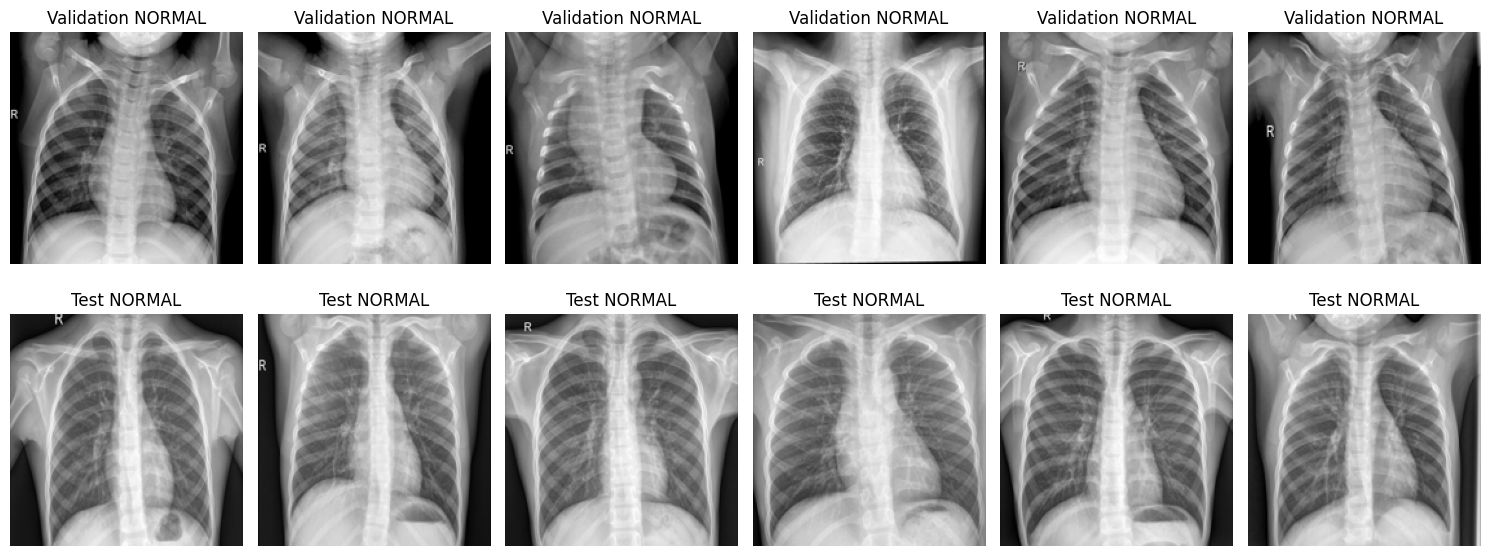

In [31]:
import numpy as np
import matplotlib.pyplot as plt

val_normal = np.where(np.asarray(y_val).ravel() == 0)[0][:6]
test_normal = np.where(np.asarray(y_test).ravel() == 0)[0][:6]

fig, axes = plt.subplots(2, 6, figsize=(15, 6))

for col, idx in enumerate(val_normal):
    axes[0, col].imshow(X_val[idx].squeeze(), cmap="gray")
    axes[0, col].set_title("Validation NORMAL")
    axes[0, col].axis("off")

for col, idx in enumerate(test_normal):
    axes[1, col].imshow(X_test[idx].squeeze(), cmap="gray")
    axes[1, col].set_title("Test NORMAL")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

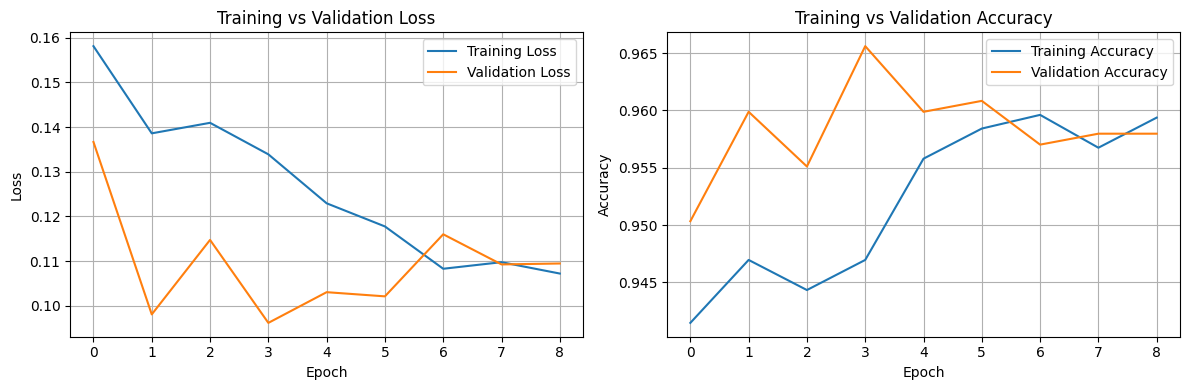

Final Training Accuracy: 0.9594
Final Validation Accuracy: 0.958
Final Training Loss: 0.1072
Final Validation Loss: 0.1095


In [32]:
import matplotlib.pyplot as plt

# Plot training and validation loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Display the final metrics
print("Final Training Accuracy:", round(history.history["accuracy"][-1], 4))
print("Final Validation Accuracy:", round(history.history["val_accuracy"][-1], 4))
print("Final Training Loss:", round(history.history["loss"][-1], 4))
print("Final Validation Loss:", round(history.history["val_loss"][-1], 4))

In [33]:
THRESHOLD = 0.7

# Predict probabilities for PNEUMONIA
y_prob = model.predict(X_test).ravel()

# Convert probabilities to class labels
y_pred = (y_prob >= THRESHOLD).astype(int)

print("Threshold:", THRESHOLD)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Threshold: 0.7


In [34]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

Accuracy: 0.8365384615384616

Confusion Matrix:
[[139  95]
 [  7 383]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.95      0.59      0.73       234
   PNEUMONIA       0.80      0.98      0.88       390

    accuracy                           0.84       624
   macro avg       0.88      0.79      0.81       624
weighted avg       0.86      0.84      0.83       624



In [35]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

for name, X, y in [
    ("VALIDATION", X_val, y_val),
    ("TEST", X_test, y_test)
]:
    probabilities = model.predict(X, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    print(f"\n{'=' * 15} {name} {'=' * 15}")
    print("Confusion matrix:")
    print(confusion_matrix(y, predictions, labels=[0, 1]))

    print("\nClassification report:")
    print(classification_report(
        y,
        predictions,
        labels=[0, 1],
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4,
        zero_division=0
    ))

    for label, class_name in [(0, "NORMAL"), (1, "PNEUMONIA")]:
        class_probs = probabilities[np.asarray(y).ravel() == label]
        print(
            f"{class_name} mean probability: "
            f"{class_probs.mean():.4f}"
        )


=============== VALIDATION ===============
Confusion matrix:
[[260  10]
 [ 26 751]]

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.9091    0.9630    0.9353       270
   PNEUMONIA     0.9869    0.9665    0.9766       777

    accuracy                         0.9656      1047
   macro avg     0.9480    0.9648    0.9559      1047
weighted avg     0.9668    0.9656    0.9659      1047

NORMAL mean probability: 0.0687
PNEUMONIA mean probability: 0.9519

=============== TEST ===============
Confusion matrix:
[[120 114]
 [  4 386]]

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.9677    0.5128    0.6704       234
   PNEUMONIA     0.7720    0.9897    0.8674       390

    accuracy                         0.8109       624
   macro avg     0.8699    0.7513    0.7689       624
weighted avg     0.8454    0.8109    0.7935       624

NORMAL mean probability: 0.4959
PNEUMONIA mean probability: 0.9782


In [36]:

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = 224

def prepare_for_mobilenet(X):
    # Resize: 180x180 -> 224x224
    X = tf.image.resize(X, (IMG_SIZE, IMG_SIZE))

    # Grayscale (1 channel) -> RGB (3 channels)
    X = tf.image.grayscale_to_rgb(X)

    # Current pixels are [0, 1].
    # MobileNetV2 preprocess_input expects [0, 255]
    # and converts them to [-1, 1].
    X = X * 255.0
    X = preprocess_input(X)

    return X

X_train_mobilenet = prepare_for_mobilenet(X_train)
X_val_mobilenet = prepare_for_mobilenet(X_val)
X_test_mobilenet = prepare_for_mobilenet(X_test)

print("Train:", X_train_mobilenet.shape)
print("Validation:", X_val_mobilenet.shape)
print("Test:", X_test_mobilenet.shape)


Train: (4185, 224, 224, 3)
Validation: (1047, 224, 224, 3)
Test: (624, 224, 224, 3)


In [37]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [38]:
base_model.trainable = False

In [39]:

mobilenet_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_mobilenetv2.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        mode="min",
        verbose=1
    )
]


In [40]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

In [41]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [67]:

history = model.fit(
    X_train_mobilenet,
    y_train,
    validation_data=(X_val_mobilenet, y_val),
    epochs=20,
    batch_size=32,
    callbacks=mobilenet_callbacks,
    class_weight=class_weights
)

Epoch 1/20
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9989 - auc: 1.0000 - loss: 0.0085 - precision: 1.0000 - recall: 0.9985
Epoch 1: val_loss did not improve from 0.05177
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9989 - auc: 1.0000 - loss: 0.0085 - precision: 1.0000 - recall: 0.9985 - val_accuracy: 0.9790 - val_auc: 0.9965 - val_loss: 0.0695 - val_precision: 0.9961 - val_recall: 0.9755 - learning_rate: 1.0000e-06
Epoch 2/20
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9974 - auc: 1.0000 - loss: 0.0096 - precision: 0.9988 - recall: 0.9977
Epoch 2: val_loss did not improve from 0.05177
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9974 - auc: 1.0000 - loss: 0.0096 - precision: 0.9988 - recall: 0.9977 - val_accuracy: 0.9799 - val_auc: 0.9964 - val_loss: 0.0725 - val_precision: 0.9961 - val_recall: 0.9768 - learning_rate: 1.0000e-06
Epoch 3/20
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9985 - auc: 1.0000 - loss: 0.0077 - precisi

In [43]:
best_model = tf.keras.models.load_model(
    "best_mobilenetv2.keras"
)

In [69]:
test_results = best_model.evaluate(
    X_test_mobilenet,
    y_test,
    verbose=1,
    return_dict=True
)

print(test_results)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6692 - auc: 0.6151 - loss: 1.3111 - precision: 0.4020 - recall: 0.6596    
{'accuracy': 0.8157051205635071, 'auc': 0.9259587526321411, 'loss': 0.7437121272087097, 'precision': 0.7744510769844055, 'recall': 0.9948717951774597}


In [71]:
y_prob = model.predict(X_test_mobilenet).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(confusion_matrix(y_test, y_pred))
print(classification_report(
    y_test,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
[[133 101]
 [  2 388]]
              precision    recall  f1-score   support

      NORMAL       0.99      0.57      0.72       234
   PNEUMONIA       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.89      0.78      0.80       624
weighted avg       0.87      0.83      0.82       624



In [72]:
base_model.trainable = True

# Freeze earlier layers; fine-tune only the later layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for a safer first experiment.
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [73]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [74]:
history = model.fit(
    X_train_mobilenet,
    y_train,
    validation_data=(X_val_mobilenet, y_val),
    epochs=20,
    batch_size=32,
    callbacks=mobilenet_callbacks,
    class_weight=class_weights
)

Epoch 1/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.9937 - auc: 0.9999 - loss: 0.0152 - precision: 0.9980 - recall: 0.9936
Epoch 1: val_loss did not improve from 0.05177
131/131 ━━━━━━━━━━━━━━━━━━━━ 22s 107ms/step - accuracy: 0.9937 - auc: 0.9999 - loss: 0.0153 - precision: 0.9980 - recall: 0.9936 - val_accuracy: 0.9723 - val_auc: 0.9913 - val_loss: 0.1034 - val_precision: 0.9640 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/20
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9958 - auc: 0.9999 - loss: 0.0146 - precision: 0.9995 - recall: 0.9948
Epoch 2: val_loss did not improve from 0.05177
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.9958 - auc: 0.9999 - loss: 0.0146 - precision: 0.9995 - recall: 0.9948 - val_accuracy: 0.9799 - val_auc: 0.9949 - val_loss: 0.0638 - val_precision: 0.9821 - val_recall: 0.9910 - learning_rate: 1.0000e-05
Epoch 3/20
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9975 - auc: 1.0000 - loss: 0.0106 - preci

In [75]:
test_results = model.evaluate(
    X_test_mobilenet,
    y_test,
    verbose=1,
    return_dict=True
)

print(test_results)

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 134ms/step - accuracy: 0.7004 - auc: 0.5902 - loss: 1.8038 - precision: 0.4082 - recall: 0.6596  
{'accuracy': 0.8237179517745972, 'auc': 0.8865384459495544, 'loss': 1.0675513744354248, 'precision': 0.7822580933570862, 'recall': 0.9948717951774597}


In [76]:
y_prob = model.predict(X_test_mobilenet).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(confusion_matrix(y_test, y_pred))
print(classification_report(
    y_test,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 201ms/step
[[126 108]
 [  2 388]]
              precision    recall  f1-score   support

      NORMAL       0.98      0.54      0.70       234
   PNEUMONIA       0.78      0.99      0.88       390

    accuracy                           0.82       624
   macro avg       0.88      0.77      0.79       624
weighted avg       0.86      0.82      0.81       624



In [77]:


normal_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(
        factor=0.03,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.03,
        width_factor=0.03,
        fill_mode="reflect"
    ),
    tf.keras.layers.RandomZoom(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect"
    )
], name="normal_augmentation")

In [78]:
# Create a dataset from the original training images and labels
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_mobilenet, y_train)
)

# Augment NORMAL images only
def augment_normal_only(image, label):

    image = tf.cond(
        tf.equal(tf.cast(label, tf.int32), 0),
        lambda: normal_augmentation(image, training=True),
        lambda: image
    )

    return image, label


train_dataset = train_dataset.map(
    augment_normal_only,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Shuffle and prepare batches
train_dataset = train_dataset.shuffle(
    buffer_size=1000,
    seed=42
)

train_dataset = train_dataset.batch(32).prefetch(
    tf.data.AUTOTUNE
)

In [79]:
import numpy as np
import tensorflow as tf

# Augmentation layers
normal_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
])

# Find NORMAL images (label 0)
normal_indices = np.where(y_train == 0)[0]

X_augmented = []
y_augmented = []

# Generate 2 new versions of each NORMAL image
for idx in normal_indices:
    image = tf.convert_to_tensor(X_train_mobilenet[idx])

    for _ in range(2):
        augmented_image = normal_augmentation(
            tf.expand_dims(image, axis=0),
            training=True
        )[0]

        X_augmented.append(augmented_image.numpy())
        y_augmented.append(0)

# Convert generated images to NumPy arrays
if X_augmented:
    X_augmented = np.stack(X_augmented).astype(np.float32)
    y_augmented = np.array(y_augmented, dtype=np.int32)

    # Add generated images to original training data
    X_train_augmented = np.concatenate(
        [X_train_mobilenet, X_augmented],
        axis=0
    )

    y_train_augmented = np.concatenate(
        [y_train, y_augmented],
        axis=0
    )
else:
    X_train_augmented = X_train_mobilenet
    y_train_augmented = y_train.copy()

print("Before augmentation:")
print("NORMAL:", np.sum(y_train == 0))
print("PNEUMONIA:", np.sum(y_train == 1))
print("Total:", len(y_train))

print("\nAfter augmentation:")
print("NORMAL:", np.sum(y_train_augmented == 0))
print("PNEUMONIA:", np.sum(y_train_augmented == 1))
print("Total:", len(y_train_augmented))

Before augmentation:
NORMAL: 1079
PNEUMONIA: 3106
Total: 4185

After augmentation:
NORMAL: 3237
PNEUMONIA: 3106
Total: 6343


Distribution BEFORE augmentation:
NORMAL: 1079
PNEUMONIA: 3106
Total: 4185

Distribution AFTER augmentation:
NORMAL: 1079
PNEUMONIA: 3106
Total: 4185


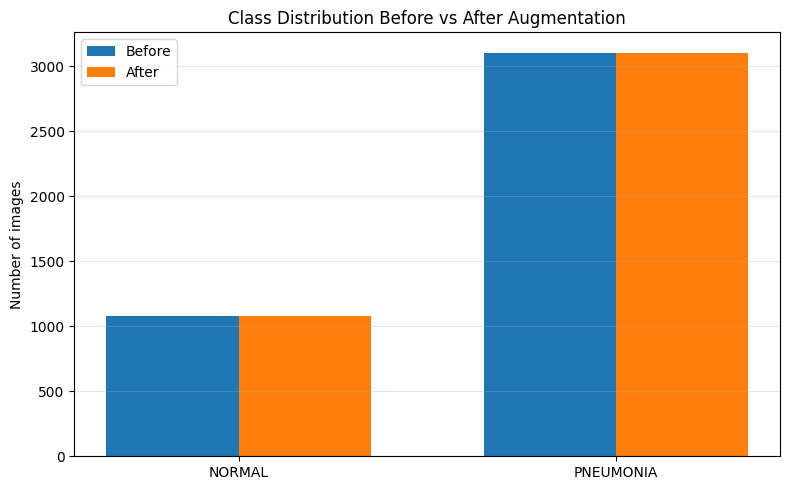

In [80]:
import numpy as np
import matplotlib.pyplot as plt

# Original distribution
normal_before = np.sum(y_train == 0)
pneumonia_before = np.sum(y_train == 1)

# Augmentation changes images, not labels or dataset size
normal_after = normal_before
pneumonia_after = pneumonia_before

print("Distribution BEFORE augmentation:")
print(f"NORMAL: {normal_before}")
print(f"PNEUMONIA: {pneumonia_before}")
print(f"Total: {len(y_train)}")

print("\nDistribution AFTER augmentation:")
print(f"NORMAL: {normal_after}")
print(f"PNEUMONIA: {pneumonia_after}")
print(f"Total: {normal_after + pneumonia_after}")

# Plot distribution
labels = ["NORMAL", "PNEUMONIA"]
before = [normal_before, pneumonia_before]
after = [normal_after, pneumonia_after]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width / 2, before, width, label="Before")
plt.bar(x + width / 2, after, width, label="After")

plt.xticks(x, labels)
plt.ylabel("Number of images")
plt.title("Class Distribution Before vs After Augmentation")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [81]:
history = model.fit(
    train_dataset,
    validation_data=(
        X_val_mobilenet,
        y_val
    ),
    epochs=20,
    callbacks=mobilenet_callbacks
)

Epoch 1/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.9968 - auc: 0.9999 - loss: 0.0103 - precision: 0.9970 - recall: 0.9987
Epoch 1: val_loss did not improve from 0.05177
131/131 ━━━━━━━━━━━━━━━━━━━━ 19s 80ms/step - accuracy: 0.9968 - auc: 0.9999 - loss: 0.0103 - precision: 0.9970 - recall: 0.9987 - val_accuracy: 0.9819 - val_auc: 0.9967 - val_loss: 0.0597 - val_precision: 0.9922 - val_recall: 0.9833 - learning_rate: 2.5000e-06
Epoch 2/20
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9995 - auc: 1.0000 - loss: 0.0035 - precision: 0.9993 - recall: 1.0000
Epoch 2: val_loss did not improve from 0.05177
131/131 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.9995 - auc: 1.0000 - loss: 0.0035 - precision: 0.9993 - recall: 1.0000 - val_accuracy: 0.9809 - val_auc: 0.9967 - val_loss: 0.0617 - val_precision: 0.9922 - val_recall: 0.9820 - learning_rate: 2.5000e-06
Epoch 3/20
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9997 - auc: 1.0000 - loss: 0.0019 - precis

In [82]:
history = model.fit(
    X_train_augmented,
    y_train_augmented,
    validation_data=(X_val_mobilenet, y_val),
    epochs=20,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9991 - auc: 1.0000 - loss: 0.0051 - precision: 0.9988 - recall: 0.9994
Epoch 1: val_loss did not improve from 0.05726
199/199 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.9991 - auc: 1.0000 - loss: 0.0051 - precision: 0.9988 - recall: 0.9994 - val_accuracy: 0.9790 - val_auc: 0.9967 - val_loss: 0.0638 - val_precision: 0.9922 - val_recall: 0.9794 - learning_rate: 1.0000e-06
Epoch 2/20
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9992 - auc: 1.0000 - loss: 0.0035 - precision: 0.9984 - recall: 1.0000
Epoch 2: val_loss did not improve from 0.05726
199/199 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.9992 - auc: 1.0000 - loss: 0.0035 - precision: 0.9984 - recall: 1.0000 - val_accuracy: 0.9799 - val_auc: 0.9967 - val_loss: 0.0607 - val_precision: 0.9896 - val_recall: 0.9833 - learning_rate: 1.0000e-06
Epoch 3/20
198/199 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9994 - auc: 1.0000 - loss: 0.0030 - precisi

In [83]:
y_prob = model.predict(X_test_mobilenet).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(confusion_matrix(y_test, y_pred))
print(classification_report(
    y_test,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
[[117 117]
 [  1 389]]
              precision    recall  f1-score   support

      NORMAL       0.99      0.50      0.66       234
   PNEUMONIA       0.77      1.00      0.87       390

    accuracy                           0.81       624
   macro avg       0.88      0.75      0.77       624
weighted avg       0.85      0.81      0.79       624

